In [ ]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import statsmodels.formula.api as smf
import yfinance as yf
from scipy import stats

SEC_HEADERS = {"User-Agent": "Linh Chi Tran linhchiemilycb@gmail.com"}  
START_FY, END_FY = 2018, 2024
OUT = Path("../data/task4")
OUT.mkdir(parents=True, exist_ok=True)
OUT.mkdir(exist_ok=True)

# 26 firms: sectors with heavy adjustments (tech, pharma) vs. light (staples, utilities)
SECTORS = {
    "AAPL": "Tech", "MSFT": "Tech", "ORCL": "Tech", "ADBE": "Tech",
    "CRM": "Tech", "INTC": "Tech", "CSCO": "Tech", "QCOM": "Tech",
    "JNJ": "Healthcare", "PFE": "Healthcare", "MRK": "Healthcare",
    "ABBV": "Healthcare", "AMGN": "Healthcare", "BMY": "Healthcare",
    "PG": "Staples", "KO": "Staples", "PEP": "Staples", "WMT": "Staples", "COST": "Staples",
    "CAT": "Industrials", "HON": "Industrials", "UNP": "Industrials",
    "DUK": "Utilities", "SO": "Utilities",
    "COP": "Energy", "CVX": "Energy",
}
TICKERS = list(SECTORS)



In [7]:
def get_cik_map():
    r = requests.get("https://www.sec.gov/files/company_tickers.json", headers=SEC_HEADERS)
    r.raise_for_status()
    return {v["ticker"]: int(v["cik_str"]) for v in r.json().values()}


def get_facts(cik):
    url = f"https://data.sec.gov/api/xbrl/companyfacts/CIK{cik:010d}.json"
    r = requests.get(url, headers=SEC_HEADERS)
    r.raise_for_status()
    time.sleep(0.15)  # SEC rate limit: max 10 requests/second
    return r.json()["facts"].get("us-gaap", {})


def annual_series(facts, tags, unit="USD", flow=True):
    """Annual values from 10-K filings, indexed by period end.
    Keeps the FIRST-filed value per period (point-in-time, no restatements = no look-ahead).
    Tags are tried in priority order; later tags only fill missing years."""
    out = None
    for tag in tags:
        units = facts.get(tag, {}).get("units", {})
        if unit not in units:
            continue
        d = pd.DataFrame(units[unit])
        d = d[d["form"].isin(["10-K", "10-K/A"])].copy()
        if d.empty:
            continue
        d["end"] = pd.to_datetime(d["end"])
        d["filed"] = pd.to_datetime(d["filed"])
        if flow:  # income / cash-flow items: keep ~12-month durations only
            if "start" not in d:
                continue
            d["start"] = pd.to_datetime(d["start"])
            d = d[(d["end"] - d["start"]).dt.days.between(350, 380)]
        if d.empty:
            continue
        d = d.sort_values("filed").groupby("end").first()[["val", "filed"]]
        out = d if out is None else out.combine_first(d)
    return out if out is not None else pd.DataFrame(columns=["val", "filed"])


def align(s, idx, tol_days=10):
    """Match a series to target dates (fiscal year ends can differ by a few days)."""
    if s.empty:
        return pd.Series(np.nan, index=idx)
    return s.sort_index().reindex(idx, method="nearest", tolerance=pd.Timedelta(days=tol_days))


def edgar_firm(cik):
    f = get_facts(cik)
    ni = annual_series(f, ["NetIncomeLoss", "ProfitLoss"])
    ocf = annual_series(f, ["NetCashProvidedByUsedInOperatingActivities",
                            "NetCashProvidedByUsedInOperatingActivitiesContinuingOperations"])
    eps = annual_series(f, ["EarningsPerShareDiluted", "EarningsPerShareBasicAndDiluted"],
                        unit="USD/shares")
    assets = annual_series(f, ["Assets"], flow=False)["val"]

    idx = pd.DatetimeIndex(ni.index)
    df = pd.DataFrame({
        "ni": ni["val"],
        "filed": ni["filed"],
        "ocf": align(ocf["val"], idx).values,
        "eps_gaap_raw": align(eps["val"], idx).values,
        "assets": align(assets, idx).values,
        "assets_prev": align(assets, idx - pd.DateOffset(years=1)).values,
    }, index=idx)
    df.index.name = "fy_end"
    return df[(df.index.year >= START_FY) & (df.index.year <= END_FY)]



In [8]:
def tz_naive(index):
    index = pd.DatetimeIndex(index)
    return index.tz_localize(None) if index.tz is not None else index


def adjusted_eps_annual(tk, fy_ends):
    """Sum of the 4 quarterly 'Reported EPS' released for each fiscal year.
    A quarter's results are released ~1-3 months after quarter end, so the window is
    (previous FY end + 100 days, FY end + 100 days]."""
    ed = tk.get_earnings_dates(limit=60)
    if ed is None or ed.empty:
        return pd.Series(np.nan, index=fy_ends)
    ed = ed.dropna(subset=["Reported EPS"])
    ed.index = tz_naive(ed.index)
    ed = ed[~ed.index.normalize().duplicated()].sort_index()
    out = {}
    for end in fy_ends:
        lo = end - pd.DateOffset(years=1) + pd.Timedelta(days=100)
        hi = end + pd.Timedelta(days=100)
        win = ed[(ed.index > lo) & (ed.index <= hi)]
        out[end] = win["Reported EPS"].sum() if len(win) == 4 else np.nan
    return pd.Series(out)


def split_factor(splits, date):
    """Cumulative split ratio after `date` (Yahoo data are restated to today's share count)."""
    return float(splits[splits.index > date].prod()) if len(splits) else 1.0



In [9]:
px = yf.download(TICKERS + ["SPY"], start=f"{START_FY}-01-01", auto_adjust=False, progress=False)
close = px["Close"]       # split-adjusted, NOT dividend-adjusted -> for scaling EPS
adj_close = px["Adj Close"]  # split + dividend adjusted -> for returns
LAST_DATE = adj_close.index[-1]


def price_on_or_before(s, date):
    s = s.loc[:date].dropna()
    return s.iloc[-1] if len(s) else np.nan


def price_on_or_after(s, date):
    s = s.loc[date:].dropna()
    return s.iloc[0] if len(s) else np.nan


def fwd_return(s, start):
    end = start + pd.Timedelta(days=365)
    if end > LAST_DATE:
        return np.nan
    return price_on_or_after(s, end) / price_on_or_after(s, start) - 1



In [10]:
cik_map = get_cik_map()
rows = []
for t in TICKERS:
    try:
        df = edgar_firm(cik_map[t])
        tk = yf.Ticker(t)
        splits = tk.splits
        splits.index = tz_naive(splits.index)
        df["eps_adj"] = adjusted_eps_annual(tk, df.index).values
        for end, r in df.iterrows():
            formation = r["filed"] + pd.Timedelta(days=1)  # 10-K is public -> no look-ahead
            ret = fwd_return(adj_close[t], formation)
            spy = fwd_return(adj_close["SPY"], formation)
            rows.append({
                "ticker": t, "sector": SECTORS[t], "fy": end.year, "fy_end": end,
                "formation": formation,
                "eps_gaap": r["eps_gaap_raw"] / split_factor(splits, r["filed"]),
                "eps_adj": r["eps_adj"],
                "price": price_on_or_before(close[t], end),
                "ni": r["ni"], "ocf": r["ocf"],
                "avg_assets": np.nanmean([r["assets"], r["assets_prev"]]),
                "ret_12m": ret, "excess_ret": ret - spy,
            })
        print(f"{t}: {len(df)} years")
    except Exception as e:
        print(f"{t}: FAILED ({e})")

panel = pd.DataFrame(rows)
panel["gap"] = (panel["eps_adj"] - panel["eps_gaap"]) / panel["price"]
panel["gap_pct"] = (panel["eps_adj"] - panel["eps_gaap"]) / panel["eps_gaap"].abs()
panel["accruals"] = (panel["ni"] - panel["ocf"]) / panel["avg_assets"]
panel.to_csv(OUT / "panel_raw.csv", index=False)

# Winsorize signals at 5/95% (small sample -> outliers dominate otherwise)
for c in ["gap", "accruals"]:
    lo, hi = panel[c].quantile([0.05, 0.95])
    panel[c + "_w"] = panel[c].clip(lo, hi)


AAPL: 7 years
MSFT: 7 years
ORCL: 7 years
ADBE: 7 years
CRM: 7 years
INTC: 7 years
CSCO: 7 years
QCOM: 7 years
JNJ: 7 years
PFE: 7 years
MRK: 7 years
ABBV: 7 years
AMGN: 7 years
BMY: 7 years
PG: 7 years
KO: 7 years
PEP: 7 years
WMT: 7 years
COST: 7 years
CAT: 7 years
HON: 7 years
UNP: 7 years
DUK: 7 years
SO: 7 years
COP: 7 years
CVX: 7 years


In [11]:
report = []
desc = panel.groupby("sector").agg(
    n=("ticker", "size"),
    median_gap_pct=("gap_pct", "median"),
    share_adj_above_gaap=("gap", lambda x: (x > 0).mean()),
    mean_accruals=("accruals", "mean"),
).round(3)
report.append("=== Descriptives by sector ===\n" + desc.to_string())
print(desc)


              n  median_gap_pct  share_adj_above_gaap  mean_accruals
sector                                                              
Energy       14           0.030                 0.500         -0.081
Healthcare   42           0.678                 0.976         -0.057
Industrials  21           0.054                 0.857         -0.022
Staples      35           0.084                 0.743         -0.043
Tech         56           0.192                 0.768         -0.061
Utilities    14           0.108                 0.929         -0.031


In [12]:
d = panel.dropna(subset=["gap_w", "accruals_w", "excess_ret"]).copy()
report.append(f"\nObservations used: {len(d)} firm-years, {d['ticker'].nunique()} firms")

for sig in ["gap_w", "accruals_w"]:
    d[sig + "_t"] = d.groupby("fy")[sig].transform(
        lambda x: pd.qcut(x.rank(method="first"), 3, labels=False)) + 1
    means = d.groupby(sig + "_t")["excess_ret"].agg(["mean", "count"])
    hi = d.loc[d[sig + "_t"] == 3, "excess_ret"]
    lo = d.loc[d[sig + "_t"] == 1, "excess_ret"]
    tstat, p = stats.ttest_ind(hi, lo, equal_var=False)
    report.append(f"\n=== Terciles on {sig} (1 = low, 3 = high) ===\n{means.round(4).to_string()}"
                  f"\nHigh - Low = {hi.mean() - lo.mean():.4f}, t = {tstat:.2f}, p = {p:.3f}")


In [13]:
model = smf.ols("excess_ret ~ gap_w + accruals_w + C(fy)", data=d).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(d["ticker"])[0]})
report.append("\n=== OLS: excess_ret ~ gap + accruals + year FE (SE clustered by firm) ===\n"
              + model.summary().tables[1].as_text())
print(model.summary().tables[1])

(OUT / "results.txt").write_text("\n".join(report))


                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        -0.0149      0.056     -0.265      0.791      -0.125       0.096
C(fy)[T.2019]    -0.0958      0.057     -1.685      0.092      -0.207       0.016
C(fy)[T.2020]    -0.0503      0.069     -0.731      0.465      -0.185       0.085
C(fy)[T.2021]     0.0252      0.055      0.462      0.644      -0.082       0.132
C(fy)[T.2022]    -0.0803      0.061     -1.313      0.189      -0.200       0.040
C(fy)[T.2023]    -0.2204      0.052     -4.269      0.000      -0.322      -0.119
C(fy)[T.2024]     0.0664      0.094      0.707      0.480      -0.118       0.250
gap_w             1.5926      1.472      1.082      0.279      -1.293       4.478
accruals_w       -0.9697      0.717     -1.352      0.176      -2.376       0.436


2206

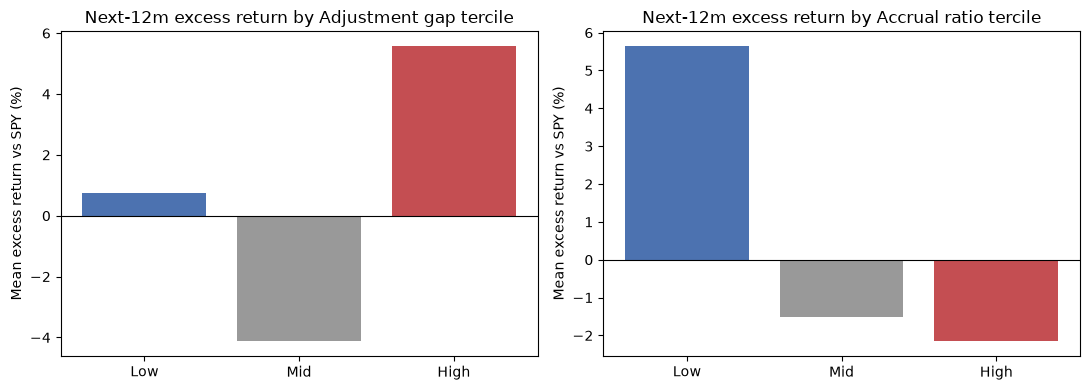

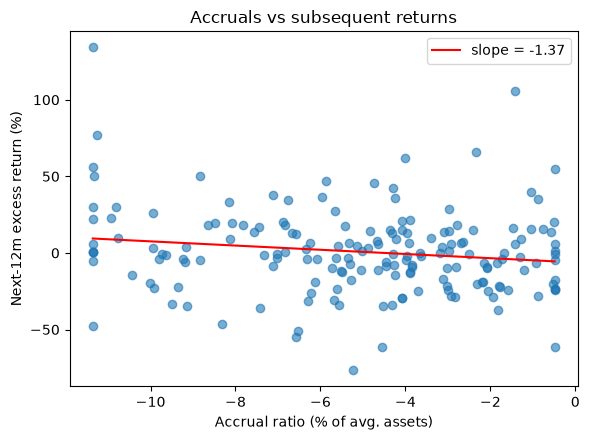


Done. Outputs in ./output: panel_raw.csv, results.txt, terciles.png, accruals_scatter.png


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, sig, title in zip(axes, ["gap_w", "accruals_w"], ["Adjustment gap", "Accrual ratio"]):
    m = d.groupby(sig + "_t")["excess_ret"].mean() * 100
    ax.bar(["Low", "Mid", "High"], m.values, color=["#4c72b0", "#999999", "#c44e52"])
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"Next-12m excess return by {title} tercile")
    ax.set_ylabel("Mean excess return vs SPY (%)")
plt.tight_layout()
plt.savefig(OUT / "terciles.png", dpi=150)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(d["accruals_w"] * 100, d["excess_ret"] * 100, alpha=0.6)
b = np.polyfit(d["accruals_w"] * 100, d["excess_ret"] * 100, 1)
xs = np.linspace(d["accruals_w"].min() * 100, d["accruals_w"].max() * 100, 50)
ax.plot(xs, np.polyval(b, xs), color="red", label=f"slope = {b[0]:.2f}")
ax.set_xlabel("Accrual ratio (% of avg. assets)")
ax.set_ylabel("Next-12m excess return (%)")
ax.set_title("Accruals vs subsequent returns")
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "accruals_scatter.png", dpi=150)
plt.show()

print("\nDone. Outputs in ./output: panel_raw.csv, results.txt, terciles.png, accruals_scatter.png")